# 06 · Single slits, double slits, and interference

A slit limits the field in position; propagation turns that aperture into a diffraction pattern. Two separated slits add coherently, so their relative phase creates interference fringes.

This is the package-user version: imports come first, and each operation is introduced when the physical question calls for it.

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from topolino import propTF


## 1. Make a single slit and observe its diffraction

An aperture is a transmission mask. A broad, nearly uniform incident field makes the role of the slit easy to see.

In [ ]:
lambda_m = 633e-9
window_m = 8e-3
n = 4096
x_m = np.linspace(-window_m/2, window_m/2, n, endpoint=False)
width_m = 100e-6
field_in = np.ones(n, dtype=complex)
slit = np.abs(x_m) <= width_m/2
field_single = propTF(field_in*slit, window_m, lambda_m, 0.50)


## 2. Add a second slit

Fields add before intensity is calculated. The cross term in `|E₁ + E₂|²` creates bright and dark fringes.

In [ ]:
spacing_m = 400e-6
mask_double = (np.abs(x_m+spacing_m/2) <= width_m/2) | (np.abs(x_m-spacing_m/2) <= width_m/2)
field_double = propTF(field_in*mask_double, window_m, lambda_m, 0.50)


## 3. Compare fringe spacing with the far-field estimate

For small angles, double-slit fringe spacing is approximately `lambda z / separation`. The finite slit width sets a broader diffraction envelope around those fringes.

In [ ]:
fringe_spacing_m = lambda_m*0.50/spacing_m
print(f"Approximate fringe spacing: {fringe_spacing_m*1e3:.3f} mm")


## Original plot code (verbatim)

The following code cells and saved outputs are copied unchanged from the cited notebook cells. Some source cells rely on variables established earlier in their original notebook.


From `paper/2025.10.09DiffractionGratings.ipynb`, cell 14.


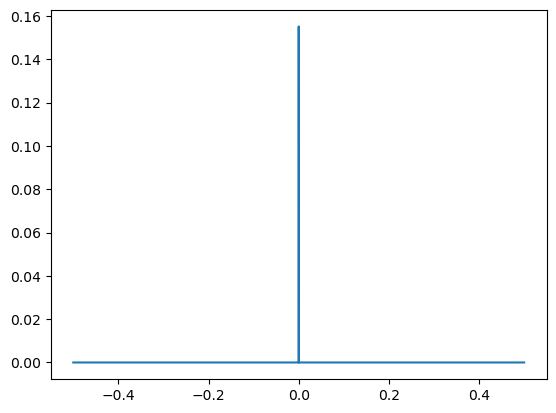

In [14]:
plt.plot(x_m,I_single_slit)

From `paper/2025.10.09DiffractionGratings.ipynb`, cell 15.


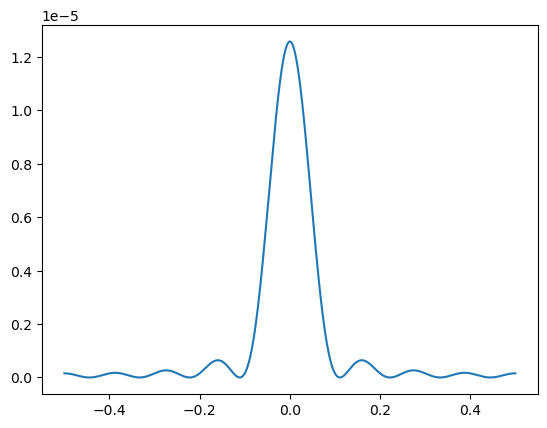

In [15]:
plt.plot(x_m,I_single_slit_out)

From `paper/2025.10.09DiffractionGratings.ipynb`, cell 16.


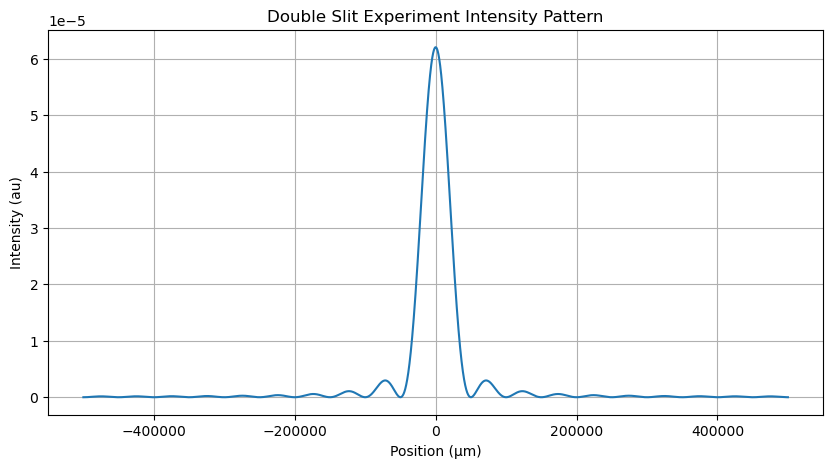

(-300.0, 300.0)

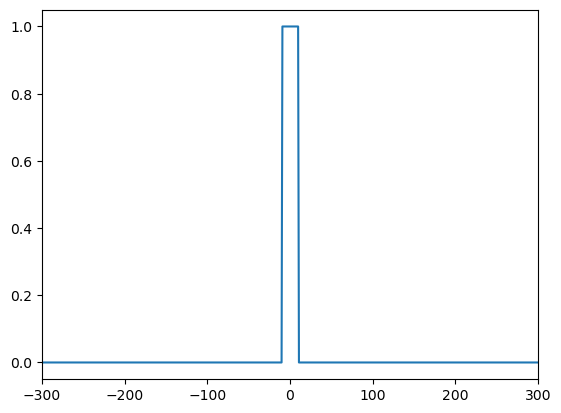

In [16]:
# 2. Double Slit Experiment

slit_spacing_m = 10e-6  # Distance between the centers of the two slits
slit1_position_m = (-slit_width_m / 2 - slit_spacing_m / 2, slit_width_m / 2 - slit_spacing_m / 2)
slit2_position_m = (-slit_width_m / 2 + slit_spacing_m / 2, slit_width_m / 2 + slit_spacing_m / 2)


double_slit = ((x_m >= slit1_position_m[0]) & (x_m <= slit1_position_m[1])) | \
              ((x_m >= slit2_position_m[0]) & (x_m <= slit2_position_m[1]))


double_slit = np.abs((np.abs(x_m) - slit_spacing_m/2) < (slit_width_m/2))


E_double_slit = Ep * double_slit
I_double_slit = np.abs(E_double_slit)**2  


Ez_double_slit = propTF(E_double_slit, Dx_m, wavelength_m, 2)
I_double_slit_out = np.abs(Ez_double_slit)**2  # Output intensity


plt.figure(figsize=(10, 5))
plt.plot(x_m * 1e6, I_double_slit_out)  
plt.title("Double Slit Experiment Intensity Pattern")
plt.xlabel("Position (µm)")
plt.ylabel("Intensity (au)")

plt.grid()
plt.show() 

plt.plot(x_m*1e6,double_slit)
plt.xlim(-300,300)


# y limit problem again ????